# StatArb Long-Short no S&P 500 — Pipeline Explicado Passo a Passo

**Projeto:** Desafio Itaú Asset Quant AI 2026
**Estratégia:** arbitragem estatística *long-short*, book de **$1 bi dollar-neutral**
(~$500mm por perna), **neutra aos fatores FF5+Momentum**, otimização convexa (cvxpy),
custos de execução **Almgren-Chriss**, hedge de beta residual com **SPY**.
**Sinal oficial:** **reversão de resíduo com z-score temporal** (`resid_ou`,
Avellaneda & Lee 2010) — escolhido por **evidência** no funil de pesquisa (seção 4.4).

Este notebook percorre o pipeline completo **usando o código de produção** (`statarb/`)
sobre os **dados reais** do S&P 500 com composição histórica correta. Cada seção
explica o *porquê* antes do *como*, no espírito do `alpha_signal_research_tutorial`.

**O mapa do pipeline** (a ordem das seções segue as dependências):

```
 (1) DADOS: S&P 500 as-of            quem existia e era negociável em cada dia
        |
 (2) MODELO DE FATORES               separa retorno em fatores + resíduo
        |--> resíduos    --> matéria-prima do SINAL (3)
        |--> betas       --> restrições do OTIMIZADOR (5) e hedge SPY
        |--> vol idio    --> escala do sinal e termo de risco
        |
 (3) SINAL resid_ou                  retorno idiossincrático acumulado, normalizado
        |
 (4) VALIDAÇÃO DE PESQUISA           IC, quintis, splits — o sinal prevê?
        |
 (5) OTIMIZADOR + (6) CUSTOS         do score à carteira executável
        |
 (7) BACKTEST OFICIAL                resid_ou no S&P 500 as-of (dev+val; holdout trancado)
```

In [1]:
# ---- Setup: localiza a raiz do projeto, importa o pacote e fixa o estilo ----
import sys, pathlib, json
raiz_projeto = pathlib.Path.cwd()
if not (raiz_projeto / "statarb").exists():
    raiz_projeto = raiz_projeto.parent      # se rodando de dentro de notebooks/
sys.path.insert(0, str(raiz_projeto))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from statarb.config import load_config, path_of
from statarb.viz.style import apply_style, PALETTE

apply_style()                                    # figsize (12,5), grid, sem spines
config = load_config()                           # todos os parametros do projeto

# Variaveis globais usadas ao longo do notebook:
book_bruto_usd = float(config["book"]["gross_usd"])       # tamanho do book: $1 bi
params_sinal   = config["signal_params"]["resid_ou"]      # {accum_days, z_window}
dias_acumulo   = int(params_sinal["accum_days"])          # J = 60 dias (Passo 1)
dias_janela_z  = int(params_sinal["z_window"])            # W = 252 dias (Passo 2)

print(f"book: ${book_bruto_usd/1e9:.0f} bi | sinal oficial: resid_ou "
      f"(acumulo J={dias_acumulo}d, janela z W={dias_janela_z}d)")

book: $1 bi | sinal oficial: resid_ou (acumulo J=60d, janela z W=252d)


## 1. Os dados: S&P 500 com composição histórica *as-of*

### 1.1 Por que "as-of"? O viés de sobrevivência

Um backtest precisa usar, em cada data, **o índice como ele era naquele dia** — não a
lista de hoje. Isso é a composição **as-of** (*"as of [uma data]"* = como estava naquela
data). Sem ela, o universo vira uma lista de vencedores por construção: as empresas que
quebraram ou foram adquiridas somem da história — o **viés de sobrevivência**
(*survivorship bias*) — e o resultado fica artificialmente inflado.

Exemplo concreto: o **Silicon Valley Bank** estava no índice até quebrar em mar/2023.
Com a lista de hoje ele nunca aparece no backtest; com a composição as-of, ele entra
até 2023 e o colapso acontece — como aconteceria na vida real.

### 1.2 Fontes (todas gratuitas e verificáveis)

| Painel | Fonte |
|---|---|
| **Composição as-of** (2.712 datas de mudança, 1996→2026) | change log oficial da Wikipedia (dataset `fja05680/sp500`) |
| **Preços/volume** ajustados | yfinance |
| **Fatores FF5+Momentum** diários | biblioteca do Ken French |
| **SPY** (hedge de beta) | yfinance |

Tudo é gravado num **schema canônico** (parquets padronizados) — o pipeline lê qualquer
fonte que escreva esse schema, sem alterar uma linha de código a jusante.

### 1.3 O viés residual, quantificado

Membership as-of resolve o viés de **seleção**; resta o de **dados**: parte dos membros
que saíram do índice não tem preço no yfinance. Medimos essa cobertura mês a mês
(está no `meta.json`) — em vez de ignorar o viés, nós o **quantificamos**: entre os
**removidos** do índice na janela, **46%** têm preço vs **99%** dos sobreviventes
(`reports/delisted_coverage_sp500.md`). *(No Russell 2000 seria 18% vs 92% — foi por
isso que a estratégia migrou para o S&P 500; ver `considerações/`.)*

#### ⚠️ Nota sobre o "gap" no início do gráfico 1.3a

O trecho inicial baixo **não é falta de dados** — é **warm-up**. E existem *dois*
warm-ups distintos, que se acumulam:

| Warm-up | Libera em | Por quê |
|---|---|---|
| **Universo negociável** (este gráfico) | jan/2019 | filtro exige ≥ 260 dias úteis de histórico por ação |
| **Sinal calculável** (o que de fato manda) | **ago/2019** | corrente: betas (252d) → resíduos → $X$ (60d) → $\mu,\sigma$ (252d de $X$) |

O elo mais longo é o $\mu/\sigma$: ele não espera 252 dias de *preço*, e sim 252 valores
de **$X$** — e cada $X$ já exigiu 60 dias de resíduos, que exigiram 252 dias para estimar
os betas. As esperas **se empilham**: ~419 dias úteis (≈1,7 ano) até o primeiro sinal.

Por isso o backtest só começa em **2020** (`backtest.start`), com folga sobre ago/2019.

painel: 684 membros historicos x 2113 dias (2018-01-02 a 2026-05-29)
cobertura media dos membros as-of: 91.7% (minima 83.8% em 2018-02-01)


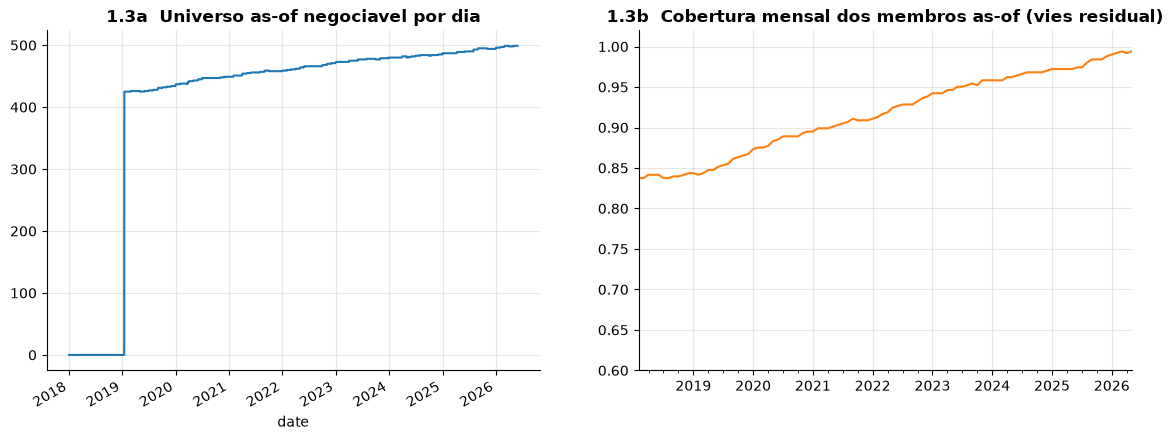

In [2]:
# ---- Carrega o painel S&P 500 as-of e define o universo negociavel ----
from statarb.data.loaders import MarketData
from statarb.data.universe import tradable_mask
from statarb.factors.betas import FactorModel

pasta_painel = raiz_projeto / "data" / "processed_sp500"

# dados_mercado: objeto com TODOS os paineis (retornos, precos, volume, membership...)
dados_mercado = MarketData.from_dir(pasta_painel, config)

# universo_negociavel: matriz booleana (data x acao) = "esta acao pode ser negociada hoje?"
#   criterios: era membro do indice na data + preco/liquidez minimos + historico suficiente
universo_negociavel = tradable_mask(dados_mercado, config)

# metadados do pull: fontes, vieses e a cobertura medida dos membros as-of
metadados = json.loads((pasta_painel / "meta.json").read_text(encoding="utf-8"))
cobertura = metadados["cobertura_membros_asof"]

n_acoes, n_dias = dados_mercado.returns.shape[1], dados_mercado.returns.shape[0]
print(f"painel: {n_acoes} membros historicos x {n_dias} dias "
      f"({dados_mercado.returns.index[0]:%Y-%m-%d} a {dados_mercado.returns.index[-1]:%Y-%m-%d})")
print(f"cobertura media dos membros as-of: {cobertura['media']:.1%} "
      f"(minima {cobertura['minima']:.1%} em {cobertura['mes_minimo']})")

# Grafico 1.3a: quantas acoes sao negociaveis a cada dia (mostra o warm-up)
# Grafico 1.3b: quantos dos membros as-of tem preco disponivel (o vies residual)
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
universo_negociavel.sum(axis=1).plot(ax=eixos[0], color=PALETTE["strategy"])
eixos[0].set_title("1.3a  Universo as-of negociavel por dia")
cobertura_mensal = pd.Series({pd.Timestamp(k): v for k, v in cobertura["serie_mensal"].items()})
cobertura_mensal.plot(ax=eixos[1], color=PALETTE["cost"])
eixos[1].set_title("1.3b  Cobertura mensal dos membros as-of (vies residual)")
eixos[1].set_ylim(0.6, 1.02)
plt.show()

## 2. O modelo de fatores — a fundação de tudo

### 2.1 A decomposição: sistemático × idiossincrático

Todo retorno diário tem duas origens: a ação se moveu **com o grupo** (mercado caiu,
ações de valor subiram...) ou se moveu **sozinha** (notícia própria, fluxo de um fundo).
O modelo de fatores separa as duas:

$$ r_{i,t} = \underbrace{\beta_i' f_t}_{\textbf{sistemático}\;(\text{fatores})}
 + \underbrace{\varepsilon_{i,t}}_{\textbf{idiossincrático}\;(\text{resíduo})} $$

Os **fatores** $f_t$ são os 6 movimentos coletivos clássicos (Fama-French 5 +
Momentum): mercado, tamanho, valor, rentabilidade, investimento e momentum — séries
públicas do Ken French. O **resíduo** $\varepsilon$ é o que sobra: a "história própria"
da ação. **É nele que mora o alfa de arbitragem estatística.**

### 2.2 Como estimamos os betas

Para **cada ação**, uma regressão dos retornos diários dela sobre os retornos dos 6
fatores, em **janela móvel de 252 dias**, re-estimada a cada **21 dias** (betas mudam
devagar; re-estimar todo dia só adiciona ruído). **Anti-lookahead estrutural:** o
resíduo do dia *s* usa apenas betas estimados **antes** de *s*.

### 2.3 As três saídas e onde cada uma é usada

| Saída | Consumida por |
|---|---|
| **Resíduos** $\varepsilon$ | o sinal `resid_ou` (seção 3) — matéria-prima |
| **Betas** $\beta$ | otimizador (**neutralidade de fatores**) + hedge SPY |
| **Vol idiossincrática** | escala do sinal + termo de risco do otimizador |

89 datas de estimacao de betas


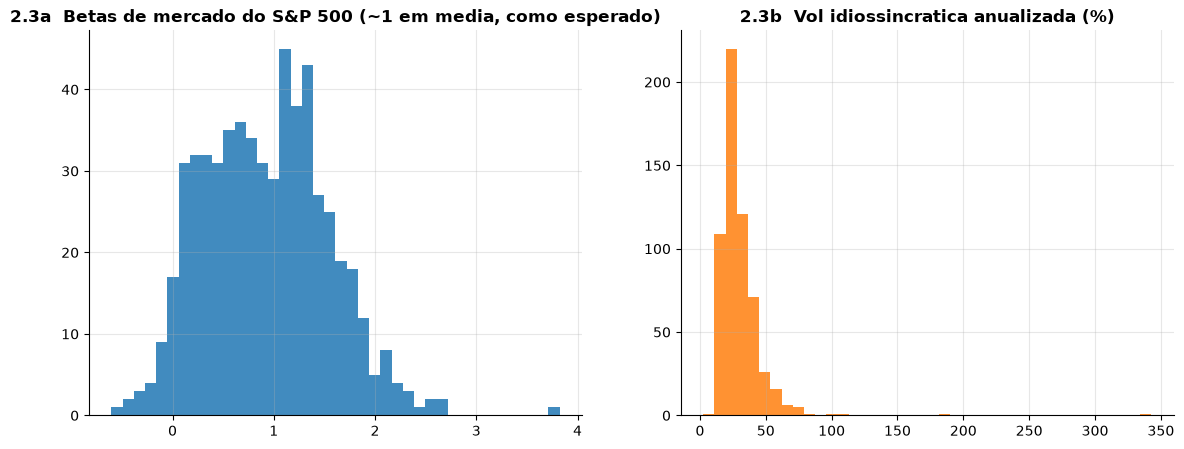

In [3]:
# ---- Estima o modelo de fatores: regressao rolling de cada acao nos 6 fatores ----
# modelo_fatores guarda 3 saidas: betas (sensibilidade a cada fator),
# residuos (o que os fatores NAO explicam) e vol idiossincratica.
modelo_fatores = FactorModel(config).fit(dados_mercado.returns, dados_mercado.factors)

ultima_data = dados_mercado.returns.index[-1]
betas_hoje = modelo_fatores.betas_asof(ultima_data)      # DataFrame: acao x 6 fatores
vol_idio_hoje = modelo_fatores.idio_asof(ultima_data)    # Series: vol diaria por acao
print(f"{len(modelo_fatores.est_index)} datas de estimacao de betas")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
betas_hoje["mkt"].hist(bins=40, ax=eixos[0], color=PALETTE["strategy"], alpha=0.85)
eixos[0].set_title("2.3a  Betas de mercado do S&P 500 (~1 em media, como esperado)")
vol_idio_anualizada = vol_idio_hoje * np.sqrt(252) * 100
vol_idio_anualizada.hist(bins=40, ax=eixos[1], color=PALETTE["cost"], alpha=0.85)
eixos[1].set_title("2.3b  Vol idiossincratica anualizada (%)")
plt.show()

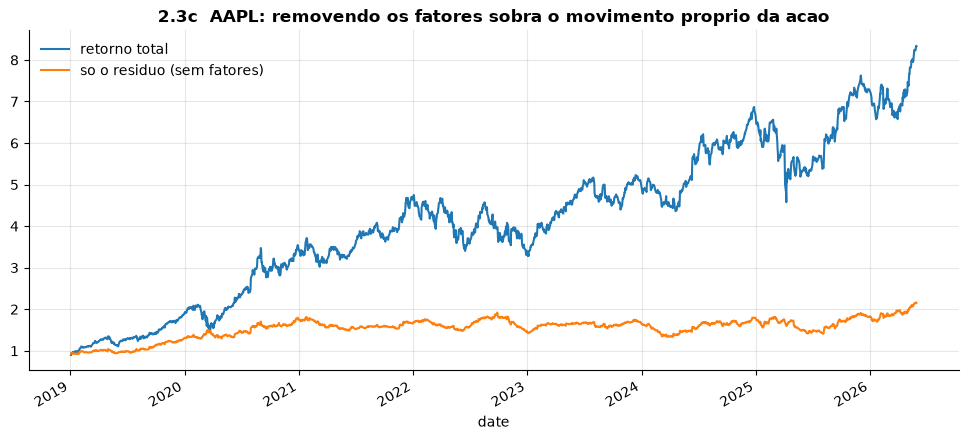

In [4]:
# ---- O residuo em acao: uma acao real, retorno total vs "historia propria" ----
# Compara o crescimento de $1 investido no retorno TOTAL (com fatores) contra
# o crescimento so do RESIDUO (removendo mercado, tamanho, valor, momentum...).
acao_exemplo = "AAPL" if "AAPL" in dados_mercado.returns.columns else dados_mercado.returns.columns[0]
residuos_diarios = modelo_fatores.residuals[acao_exemplo].dropna()   # a serie de epsilon
retornos_totais = dados_mercado.returns[acao_exemplo].loc[residuos_diarios.index]

fig, eixo = plt.subplots()
(1 + retornos_totais).cumprod().plot(ax=eixo, label="retorno total", color=PALETTE["strategy"])
(1 + residuos_diarios).cumprod().plot(ax=eixo, label="so o residuo (sem fatores)", color=PALETTE["cost"])
eixo.set_title(f"2.3c  {acao_exemplo}: removendo os fatores sobra o movimento proprio da acao")
eixo.legend(); plt.show()

## 3. O sinal oficial: `resid_ou` (reversão do retorno idiossincrático)

**De onde viemos:** a seção 2 nos deu, para cada ação e cada dia, o **resíduo** ε — o
retorno que os fatores *não* explicam. **O que fazemos agora:** transformar esses
resíduos no sinal de alfa que vai ordenar o universo.

Antes da matemática, vale fixar a anatomia de **qualquer** sinal de alfa. Ele tem três
camadas, e vamos construí-las nesta ordem:

1. **A tese** — a *crença econômica* sobre por que algo mensurável antecipa o desempenho futuro;
2. **A métrica** — o *número por ação* que traduz essa tese em algo calculável;
3. **O sinal** — a métrica *padronizada entre as ações*, pronta para ranquear o universo.

### 3.1 A tese

Tudo começa por uma crença (Avellaneda & Lee, 2010, *arbitragem estatística*):

> Quando o **retorno idiossincrático acumulado** de uma ação se afasta anormalmente do
> **seu próprio nível médio recente**, esse afastamento costuma ser **sobre-reação a
> fluxo** (liquidez, rebalanceamento de fundos), e não informação nova. E sobre-reação
> **se desfaz**: o acúmulo tende a **reverter ao nível normal daquela ação** no horizonte
> de ~1 mês.

Note o ponto de referência: a reversão é ao **nível médio da própria ação**, não a zero —
é exatamente isso que a métrica (seção 3.2) mede.

A lógica do lucro é econômica: um vendedor apressado empurra o preço para longe do
equilíbrio; quem compra dele **provê liquidez** e é remunerado quando o preço volta.
Compramos o exagero para baixo e vendemos o exagero para cima.

*Por que ~1 mês?* Os dados (seção 4.4) mostram que a reversão **rápida de 5 dias morreu**
em large caps (arbitrada por HFT), mas a do horizonte **mensal sobrevive** — é essa que operamos.

### 3.2 A métrica

A tese fala em **afastamento do próprio nível normal**. Traduzi-la em número exige, então,
responder duas perguntas — e cada uma é um passo:

1. *Quanto* esta ação acumulou de retorno próprio? → **Passo 1**
2. *Quão longe* isso está do que é normal **para ela**? → **Passo 2**

**Passo 1 — Acumular o retorno idiossincrático:**

$$ X_i(t) = \sum_{k=0}^{J-1} \varepsilon_{i,\,t-k} \qquad (J = 60\text{ dias úteis}) $$

$X_i$ é o **retorno idiossincrático acumulado**: o quanto a ação andou *por conta
própria* nos últimos ~3 meses. Economicamente, é o **afastamento do equilíbrio de
fatores** que a tese diz que reverte. Resíduos de um único dia são ruído; somá-los revela
a tendência.


**Passo 2 — Comparar com o histórico da PRÓPRIA ação:**

$$ s_i(t) = -\,\frac{X_i(t) - \mu_i(t)}{\sigma_i(t)} $$

Aqui $\mu_i$ e $\sigma_i$ são a **média e o desvio-padrão móveis do próprio $X_i$**
(janela $W = 252$ dias). A pergunta respondida é: *"esse acúmulo é grande **para ESTA
ação**?"* — cada ação vira a sua própria régua, o que remove diferenças de escala (uma
biotech volátil vs. uma utility calma). O sinal de menos **inverte** o resultado: acúmulo
muito **acima** do normal dela → esticada para cima → "cara" → candidata a **short**;
muito **abaixo** → "barata" → **long**.

Esse $s_i$ é a **métrica**: um número por ação que já mede o esticamento relativo — mas
ainda na escala individual de cada uma.

#### As camadas, do dado bruto ao score (exemplo real: AAPL)

Vale fixar que cada camada é construída sobre a anterior — e que **$X$ é uma série
diária**: todo dia calculamos um novo acúmulo de 60 dias. É sobre essa série de $X$ que
tiramos média e desvio-padrão (nunca sobre o preço).

| Camada | O que representa | Valor |
|---|---|---:|
| $\varepsilon$ (resíduo diário) | quanto a ação andou sozinha **naquele dia** | −0,42% |
| $X$ (acúmulo de 60d) | quanto ela andou sozinha em **~3 meses** | **+15,75%** |
| $\mu$ (média de $X$, 252d) | o nível **típico** desse acúmulo para a AAPL | **+4,55%** |
| $\sigma$ (desvio-padrão de $X$, 252d) | o quanto esse acúmulo **costuma oscilar** | **10,99%** |
| $s$ (métrica) | $-(15{,}75 - 4{,}55)/10{,}99$ | **−1,02** |

**Leitura:** *a AAPL normalmente acumula ~+4,5% de retorno próprio em 3 meses; hoje
acumulou +15,75% — 1 desvio-padrão acima do normal dela → esticada para cima →
candidata a **short**.* Note que o preço (US$ 312, média anual US$ 251) **não entra em
lugar nenhum**: trabalhamos apenas com retornos.

### 3.3 O sinal

Falta um passo para a métrica virar sinal: torná-la **comparável entre as ações**.

**Passo 3 — Padronizar no corte transversal (todo dia):** calcula-se a **média
$\bar{s}$ e o desvio-padrão $\sigma_s$ dos $s_i$ de todas as ações daquele dia**, e cada
ação é padronizada por eles:

$$ z_i = \frac{s_i - \bar{s}}{\sigma_s} $$

**O resultado é o sinal `resid_ou`:** um número por ação, por dia, entre −3 e +3.
Positivo = retorno idiossincrático esticado para *baixo* → espera-se a volta para cima →
**compra**; negativo → **venda**. É esse vetor que alimenta o otimizador (seção 5).

> **Métrica × sinal — a distinção que importa:** a *métrica* ($s_i$, passos 1–2) mede o
> esticamento de cada ação contra **ela mesma**; o *sinal* (passo 3) coloca todas na
> **mesma régua** para dizer *quem está mais esticado que quem hoje*. Um book long-short
> ganha com o **ranking relativo**, não com o nível absoluto — por isso o passo 3 é
> indispensável.

### 3.4 Anti-lookahead

Por construção, todos os passos usam apenas janelas **para trás** (rolling) e resíduos
calculados com betas **passados**. Um teste automatizado
(`test_signal_no_lookahead[resid_ou]`) confirma: o sinal na data *t* é idêntico com ou
sem o futuro no painel.

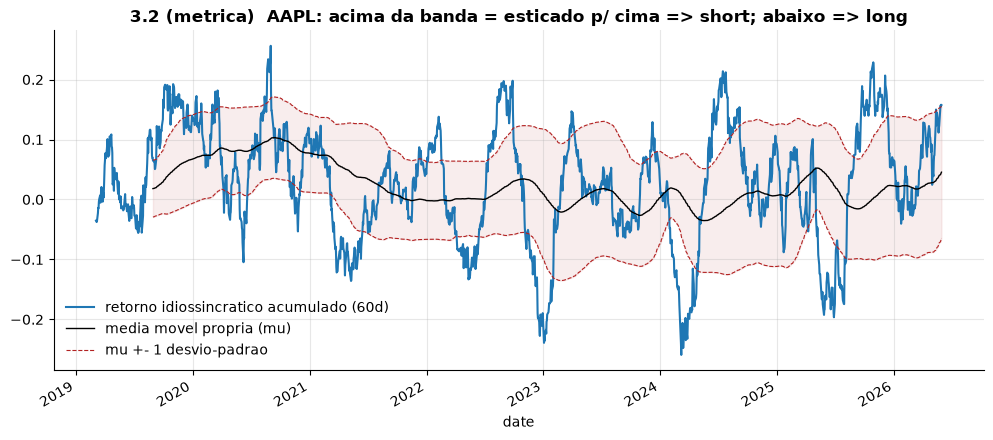

In [5]:
# ---- A METRICA (passos 1 e 2) visivel em UMA acao ----
# Passo 1: retorno_idio_acumulado = soma dos ultimos 60 residuos (o "X" da formula)
# Passo 2: compara esse acumulo com a media/desvio moveis DELE MESMO (janela 252d)
# As bandas tracejadas sao as linhas de score = +-1 desenhadas em escala de retorno.
from statarb.signals import build_signal

retorno_idio_acumulado = (modelo_fatores.residuals[acao_exemplo]
                          .rolling(dias_acumulo, min_periods=int(dias_acumulo * 0.7)).sum())
media_movel_propria  = retorno_idio_acumulado.rolling(dias_janela_z, min_periods=dias_janela_z // 2).mean()
desvio_movel_proprio = retorno_idio_acumulado.rolling(dias_janela_z, min_periods=dias_janela_z // 2).std()

banda_superior = media_movel_propria + desvio_movel_proprio   # score = -1 (esticado p/ cima)
banda_inferior = media_movel_propria - desvio_movel_proprio   # score = +1 (esticado p/ baixo)

fig, eixo = plt.subplots()
retorno_idio_acumulado.plot(ax=eixo, color=PALETTE["strategy"],
    label=f"retorno idiossincratico acumulado ({dias_acumulo}d)")
media_movel_propria.plot(ax=eixo, color="k", lw=1, label="media movel propria (mu)")
banda_superior.plot(ax=eixo, color=PALETTE["drawdown"], ls="--", lw=0.8, label="mu +- 1 desvio-padrao")
banda_inferior.plot(ax=eixo, color=PALETTE["drawdown"], ls="--", lw=0.8, label="_")
eixo.fill_between(retorno_idio_acumulado.index, banda_inferior, banda_superior,
                  alpha=0.08, color=PALETTE["drawdown"])
eixo.set_title(f"3.2 (metrica)  {acao_exemplo}: acima da banda = esticado p/ cima => short; abaixo => long")
eixo.legend(); plt.show()

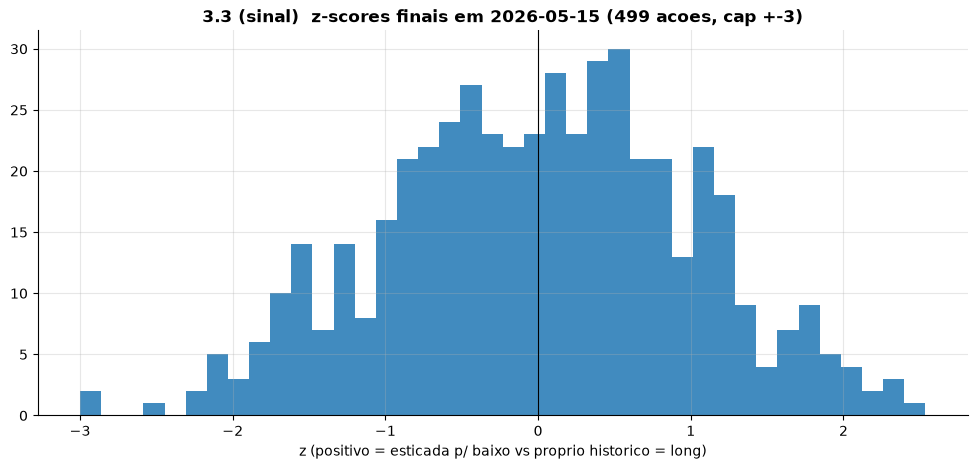

5 mais 'baratas' (long):  APH, GE, RTX, ZTS, HUBB
5 mais 'caras'  (short): CSCO, PANW, QCOM, ESS, CBOE


In [6]:
# ---- O SINAL (passo 3): a metrica padronizada ENTRE as acoes de um mesmo dia ----
# sinal_resid_ou.compute() faz os 3 passos e devolve o z-score final por acao.
sinal_resid_ou = build_signal(config, "resid_ou")

data_exemplo = dados_mercado.returns.index[-10]
acoes_do_dia = list(universo_negociavel.columns[universo_negociavel.loc[data_exemplo]])

# zscores: Series (acao -> score entre -3 e +3). Positivo = candidata a compra.
zscores = sinal_resid_ou.compute(dados_mercado, modelo_fatores, data_exemplo, acoes_do_dia)

fig, eixo = plt.subplots()
zscores.hist(bins=40, ax=eixo, color=PALETTE["strategy"], alpha=0.85)
eixo.axvline(0, color="k", lw=0.8)
eixo.set_title(f"3.3 (sinal)  z-scores finais em {data_exemplo:%Y-%m-%d} "
               f"({len(zscores)} acoes, cap +-3)")
eixo.set_xlabel("z (positivo = esticada p/ baixo vs proprio historico = long)")
plt.show()

print("5 mais 'baratas' (long): ", ", ".join(zscores.nlargest(5).index))
print("5 mais 'caras'  (short):", ", ".join(zscores.nsmallest(5).index))

## 4. O sinal prevê? IC, quintis e o funil

### 4.1 Information Coefficient (IC)

**IC** = correlação (de postos, Spearman) entre o z-score de hoje e o **retorno residual
futuro**. Régua: IC de **0,03–0,05 já é bom** em ações — o lucro vem de acertar *pouco*
em *muitas* ações ao mesmo tempo (**Lei Fundamental de Grinold**: IR ≈ IC·√breadth).
Medimos contra o retorno **residual** (e não o total) porque a carteira é fator-neutra —
o que importa é prever o movimento idiossincrático.

### 4.2 Protocolo anti-overfitting

- **Execução defasada**: o score da data *t* é confrontado com o retorno de **t+2 em
  diante** (a posição só existiria a partir do fechamento de t+1 — sem lookahead);
- **Splits temporais**: **dev** (2020–22) e **validação** (2023) separados; o
  **holdout** (2024+) fica trancado para uma única ida final.

### 4.3 A escada de quintis

Ordenamos o universo pelo z-score e dividimos em 5 grupos: um sinal saudável mostra
**escada monotônica** — o quintil comprado rende mais que o vendido, com os do meio
no meio.

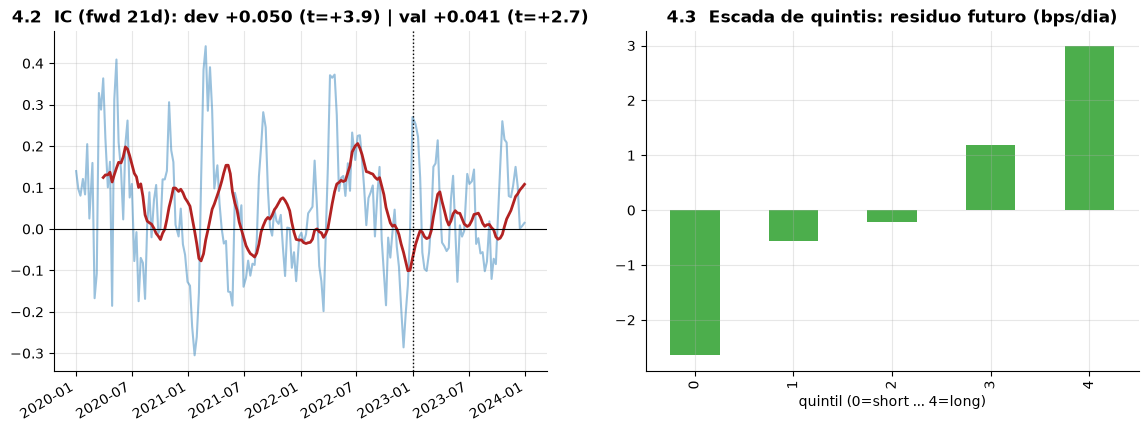

In [7]:
# ---- Mede o poder preditivo do sinal: IC e escada de quintis ----
# Para cada data da grade: calcula o sinal, olha o retorno RESIDUAL dos 21 dias
# seguintes (a partir de t+2, respeitando o lag de execucao) e mede a correlacao.
horizonte_dias = 21                                  # horizonte natural do sinal (~1 mes)
datas_painel = dados_mercado.returns.index
pos_inicio = datas_painel.searchsorted(pd.Timestamp(config["backtest"]["start"]))
fim_dev = pd.Timestamp(config["funnel"]["dev_end"])   # fim do periodo de desenvolvimento
fim_val = pd.Timestamp(config["funnel"]["val_end"])   # fim da validacao (holdout depois)

ic_por_data = []          # lista de (data, IC daquele dia)
retorno_por_quintil = []  # retorno futuro medio de cada quintil, por data

for pos in range(pos_inicio, len(datas_painel) - horizonte_dias - 2, 5):
    data = datas_painel[pos]
    if data > fim_val:                               # holdout trancado (protocolo)
        break

    acoes_hoje = list(universo_negociavel.columns[universo_negociavel.loc[data]])
    zscores_hoje = sinal_resid_ou.compute(dados_mercado, modelo_fatores, data, acoes_hoje)
    if len(zscores_hoje) < 200:
        continue

    # retorno residual acumulado de t+2 ate t+2+21 (o que o sinal tenta prever)
    retorno_futuro = modelo_fatores.residuals.iloc[pos + 2 : pos + 2 + horizonte_dias] \
                                   .sum(min_count=int(horizonte_dias * 0.7))
    acoes_validas = zscores_hoje.index.intersection(retorno_futuro.dropna().index)

    ic_por_data.append((data, spearmanr(zscores_hoje[acoes_validas],
                                        retorno_futuro[acoes_validas])[0]))
    quintil = pd.qcut(zscores_hoje[acoes_validas].rank(method="first"), 5, labels=False)
    retorno_por_quintil.append(retorno_futuro[acoes_validas].groupby(quintil).mean())

serie_ic = pd.Series(dict(ic_por_data))
# converte o retorno de cada quintil para bps por dia (mais legivel)
quintis_bps_dia = pd.concat(retorno_por_quintil, axis=1).mean(axis=1) * 1e4 / horizonte_dias

ic_dev = serie_ic[serie_ic.index <= fim_dev]         # periodo de desenvolvimento
ic_val = serie_ic[serie_ic.index > fim_dev]          # periodo de validacao
t_stat = lambda s: s.mean() / s.std() * np.sqrt(len(s))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
serie_ic.plot(ax=eixos[0], color=PALETTE["strategy"], alpha=0.45)
serie_ic.rolling(13).mean().plot(ax=eixos[0], color=PALETTE["drawdown"], lw=2)
eixos[0].axvline(fim_dev, color="k", ls=":", lw=1)   # linha divisoria dev | val
eixos[0].axhline(0, color="k", lw=0.8)
eixos[0].set_title(f"4.2  IC (fwd {horizonte_dias}d): "
                   f"dev {ic_dev.mean():+.3f} (t={t_stat(ic_dev):+.1f}) | "
                   f"val {ic_val.mean():+.3f} (t={t_stat(ic_val):+.1f})")
quintis_bps_dia.plot(kind="bar", ax=eixos[1], color=PALETTE["iwm"], alpha=0.85)
eixos[1].set_title("4.3  Escada de quintis: residuo futuro (bps/dia)")
eixos[1].set_xlabel("quintil (0=short ... 4=long)")
plt.show()

### 4.4 Por que os outros sinais foram cortados (o funil)

Testamos **8 candidatos** da literatura no mesmo protocolo (`scripts/04_signal_funnel.py`;
resultados em `reports/funnel.md`). Resumo do veredito no S&P 500:

| Sinal | Resultado | Por quê |
|---|---|---|
| **resid_ou** | ✅ **único robusto** (IC21 t≈4 dev / t≈2 val) | reversão idiossincrática lenta sobrevive em large caps |
| reversão 5d | 🟡 fraca/inconsistente | arbitrada por HFT em large caps |
| trend, MAD, seasonality, left-tail | ❌ IC ≈ 0 | são em grande parte **proxies de fator** — a previsão deles mora nos fatores, que nós **neutralizamos** |
| STR-turnover | 🟡 fraco e redundante | primo do resid_ou; no **blend** não agregou nada (testado) |
| E/P | ⛔ sem EPS gratuito point-in-time | além de ser ~fator valor (seria neutralizado) |

**Lição de método:** num book fator-neutro, o funil mede o IC contra o retorno
*residual* — sinais que vivem de exposição a fator morrem **por construção**. O que
sobra é alfa idiossincrático puro. Um sinal robusto e bem entendido > um blend inflado
(o edital diz o mesmo: *estratégia simples bem executada supera complexa mal justificada*).

## 5. Do sinal ao portfólio: o otimizador convexo

O z-score vira **retorno esperado**: $\alpha_i = z_i \times$ (bps por unidade de z)
$\times$ (horizonte de ~21 dias — a posição rende até a reversão se completar, e esse
retorno acumulado compete com o **custo de entrada**, pago uma vez). A cada
rebalanceamento resolve-se:

$$ \max_w \;\; \alpha'w \;-\; \lambda\,(w'\Sigma w) \;-\; \text{custo}_{AC}(w - w_{prev}) $$

| Restrição | Significado |
|---|---|
| $\lvert\sum_i w_i\rvert \le 0{,}002$ | **dollar-neutral**: ~$500mm long, ~$500mm short |
| $\lVert w \rVert_1 \le 1$ | orçamento bruto de $1 bi |
| $\lvert B'w \rvert \le 0{,}02$ | **neutralidade a cada fator** — o retorno vem do resíduo, não de apostas em mercado/valor/momentum |
| $\lvert \sum_{i \in setor} w_i \rvert \le 5\%$ | **neutralidade setorial** — o resíduo FF não remove indústria; sem isso o book viraria aposta setorial disfarçada |
| $\lvert w_i \rvert \le \min(0{,}5\%,\, ADV_i/G)$ | concentração + liquidez |
| $\lvert \Delta w_i \rvert \le 5\%\, ADV_i/G$ | participação máxima no volume diário |


Tudo **convexo** → solução global única. A **covariância** entra na forma fatorada
$\Sigma = B F B' + D$ (nunca a matriz N×N — com N≈500 > T seria ruído). Um **portão de
viabilidade** rejeita soluções imprecisas do solver que violem o mandato. Após cada
rebalanceamento, o beta de mercado residual é zerado com **SPY** (dollar-neutral ≠
beta-neutral).

posicoes: 248 | gross: 1.000 do book | net: -0.00200
maior |net setorial|: 0.050 (limite 0.05) -- neutralidade setorial OK


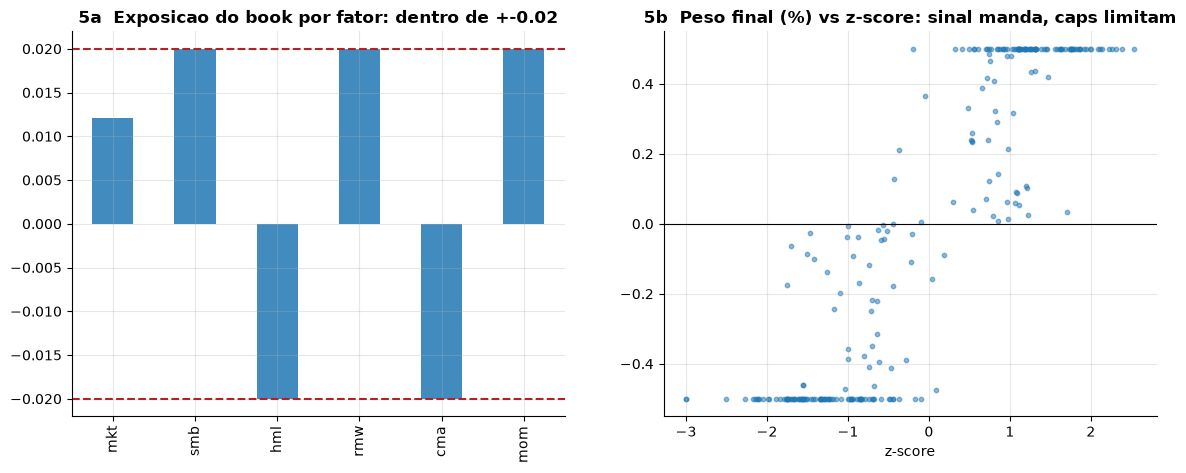

In [ ]:
# ---- Do sinal ao portfolio: monta os insumos e resolve o otimizador ----
from statarb.costs.almgren_chriss import ACCostModel
from statarb.portfolio.optimizer import optimize_weights, to_series
from statarb.risk.covariance import factor_cov_chol, total_vol

# 1) Ações elegíveis: precisam ter sinal, betas, vol idio e liquidez conhecidos
betas_data = modelo_fatores.betas_asof(data_exemplo)
vol_idio_data = modelo_fatores.idio_asof(data_exemplo)
acoes = sorted(set(zscores.index) & set(betas_data.index) & set(vol_idio_data.index))
liquidez_diaria = dados_mercado.adv.loc[data_exemplo].reindex(acoes)   # ADV em USD
acoes = [nome for nome, tem_adv in zip(acoes, liquidez_diaria.notna().values) if tem_adv]

# 2) Insumos do otimizador (todos alinhados na mesma ordem de `ações`)
retorno_esperado = zscores.reindex(acoes).values * 5e-4 * 21   # 5 bps/z x horizonte 21d
matriz_betas = betas_data.reindex(acoes).values                # (n_acoes x 6 fatores)
vol_idio = vol_idio_data.reindex(acoes).values                 # vol idiossincratica diaria
chol_cov_fatores = factor_cov_chol(dados_mercado.factors, data_exemplo, 252)
vol_total = total_vol(matriz_betas, chol_cov_fatores, vol_idio)  # usada no custo
adv_usd = dados_mercado.adv.loc[data_exemplo].reindex(acoes).values
setores = dados_mercado.sectors.reindex(acoes).fillna("Unknown").values

# 3) Resolve: maximiza alfa - risco - custo, sujeito a todo o mandato
pesos_array = optimize_weights(
    alpha=retorno_esperado, B=matriz_betas, F_chol=chol_cov_fatores, ivol=vol_idio,
    sigma_total=vol_total, adv=adv_usd, w_prev=np.zeros(len(acoes)),
    cost_model=ACCostModel(config), cfg=config, sectors=setores)

pesos = to_series(pesos_array, acoes)          # Series: acao -> peso (fracao do book)
net_por_setor = pd.Series(pesos_array, index=acoes).groupby(pd.Series(setores, index=acoes)).sum()

print(f"posicoes: {(pesos != 0).sum()} | gross: {pesos.abs().sum():.3f} do book "
      f"| net: {pesos.sum():+.5f}")
print(f"maior |net setorial|: {net_por_setor.abs().max():.3f} (limite 0.05) "
      f"-- neutralidade setorial OK")

# 4) Diagnostico: o book ficou neutro? o peso segue o sinal?
exposicao_por_fator = pd.Series(matriz_betas.T @ pesos_array,
                                index=list(dados_mercado.factors.columns))
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
exposicao_por_fator.plot(kind="bar", ax=eixos[0], color=PALETTE["strategy"], alpha=0.85)
eixos[0].axhline(0.02, color=PALETTE["drawdown"], ls="--")
eixos[0].axhline(-0.02, color=PALETTE["drawdown"], ls="--")
eixos[0].set_title("5a  Exposicao do book por fator: dentro de +-0.02")
eixos[1].scatter(zscores.reindex(pesos.index), pesos * 100, s=10, alpha=0.5,
                 color=PALETTE["strategy"])
eixos[1].axhline(0, color="k", lw=0.8)
eixos[1].set_title("5b  Peso final (%) vs z-score: sinal manda, caps limitam")
eixos[1].set_xlabel("z-score")
plt.show()

## 6. Custos de execução e convenção temporal

**Almgren-Chriss:** negociar $Q num papel com volume diário $ADV$ custa
*spread* + **impacto temporário** ($\propto\sigma\sqrt{Q/ADV}$, a "lei da raiz") +
**impacto permanente**. O MESMO modelo entra como penalidade no otimizador e como débito
no backtest — a carteira nasce ciente do próprio *footprint*.

**Convenção anti-lookahead do backtest** (quando formos rodá-lo):

```
close t   : sinal (dados <= t) -> otimizador -> pesos-alvo
close t+1 : execucao MOC + custos debitados
t+1 -> t+2: nova posicao comeca a render
```

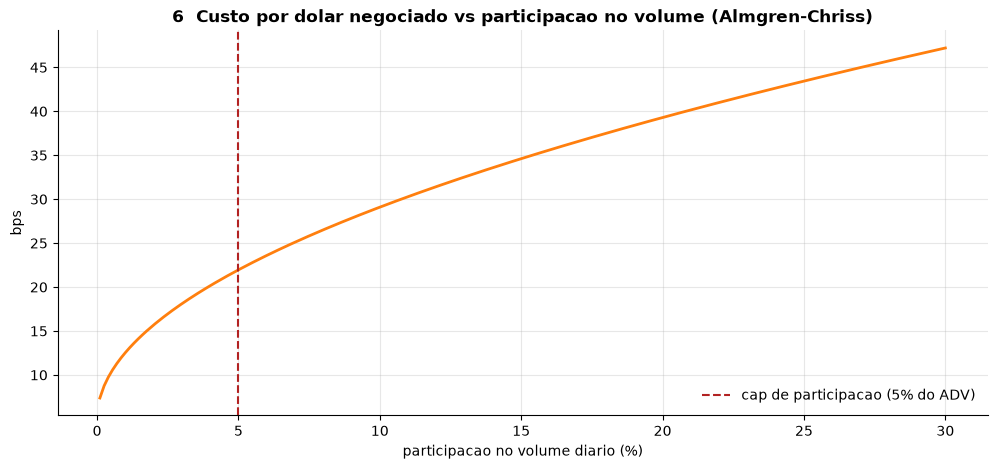

In [9]:
# ---- Curva de custo: quanto custa negociar, por participacao no volume ----
# Formula Almgren-Chriss: spread + impacto temporario (raiz) + impacto permanente (linear)
participacao_adv = np.linspace(0.001, 0.30, 200)     # 0,1% a 30% do volume diario
vol_diaria_tipica = 0.015                            # 1,5% ao dia (large cap tipica)
coef_impacto_temp = float(config["costs"]["ac_eta"])      # eta
coef_impacto_perm = float(config["costs"]["ac_gamma"])    # gamma
spread_bps = float(config["costs"]["spread_bps"])         # meio-spread + taxas

custo_bps = (spread_bps
             + 1e4 * (coef_impacto_temp * vol_diaria_tipica * np.sqrt(participacao_adv)
                      + 0.5 * coef_impacto_perm * vol_diaria_tipica * participacao_adv))

fig, eixo = plt.subplots()
eixo.plot(participacao_adv * 100, custo_bps, color=PALETTE["cost"], lw=2)
eixo.axvline(5, color=PALETTE["drawdown"], ls="--", label="cap de participacao (5% do ADV)")
eixo.set_title("6  Custo por dolar negociado vs participacao no volume (Almgren-Chriss)")
eixo.set_xlabel("participacao no volume diario (%)"); eixo.set_ylabel("bps"); eixo.legend()
plt.show()

## 7. O backtest oficial: `resid_ou` no S&P 500 as-of (dev+val)

**De onde viemos:** sinal validado em pesquisa (IC, seção 4) e carteira bem definida
(otimizador + custos, seções 5–6). **O que fazemos aqui:** a simulação completa e
oficial — sinal → otimizador (com TODAS as restrições, inclusive a **setorial**) →
custos Almgren-Chriss → execução t+1 → hedge SPY → P&L dia a dia.

**Janela: 2020 → 2023 (dev+validação). O holdout (2024+) permanece TRANCADO** — será
usado uma única vez, na decisão final (protocolo anti-overfitting).

*Os resultados abaixo são lidos de `reports/sp500_dev_val/` (gerados por
`scripts/02_run_backtest.py --data processed_sp500 --bt-end 2023-12-31 --tag sp500_dev_val`).*

In [10]:
# ---- Carrega os resultados do backtest oficial (rodado por scripts/02) ----
# resultado_diario: uma linha por dia (P&L, custos, gross/net, exposicoes, turnover)
# metricas: o resumo consolidado (Sharpe, drawdown, turnover anual...)
pasta_backtest = raiz_projeto / "reports" / "sp500_dev_val"
resultado_diario = pd.read_parquet(pasta_backtest / "results_daily.parquet")
metricas = json.loads((pasta_backtest / "metrics.json").read_text(encoding="utf-8"))

max_net_setorial = (float(resultado_diario["max_sector_net"].max())
                    if "max_sector_net" in resultado_diario else float("nan"))

resumo_backtest = pd.Series({
    "Sharpe bruto": metricas["sharpe_gross"],
    "Sharpe liquido": metricas["sharpe_net"],
    "Retorno liquido (% a.a. do gross)": metricas["ann_return_net_pct"],
    "Vol (% a.a.)": metricas["ann_vol_pct"],
    "Max drawdown (%)": metricas["max_drawdown_pct"],
    "Turnover (x gross/ano)": metricas["ann_turnover_x"],
    "Custos (bps do gross/ano)": metricas["costs_bps_of_gross_per_year"],
    "Gross medio": metricas["avg_gross"],
    "|Net| maximo": metricas["max_abs_net"],
    "Max |expo fator|": metricas["max_abs_factor_expo"],
    "Max |net setorial|": max_net_setorial,
    "Posicoes (media)": metricas["avg_n_positions"],
    "P&L liquido acumulado (USD mm)": metricas["pnl_net_total_usd_mm"],
}).round(3)
resumo_backtest.to_frame("valor")

,valor
Sharpe bruto,0.532
Sharpe liquido,0.198
Retorno liquido (% a.a. do gross),1.182
Vol (% a.a.),5.958
Max drawdown (%),-10.899
Turnover (x gross/ano),15.059
Custos (bps do gross/ano),198.271
Gross medio,0.999
|Net| maximo,0.002
Max |expo fator|,0.592


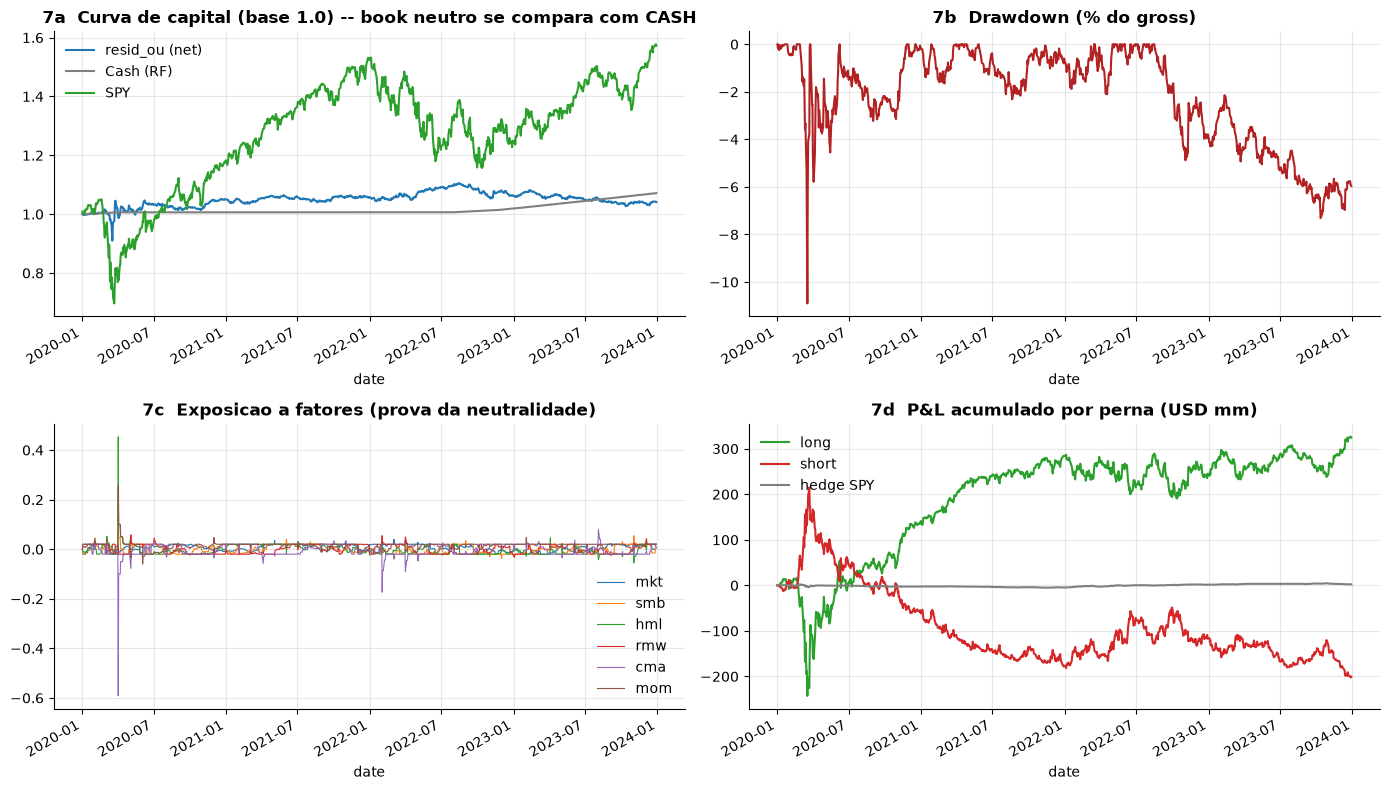

Por ano (ret liq % a.a. | Sharpe):
  2020:  +5.40%  |  +0.52
  2021:  +0.68%  |  +0.22
  2022:  +0.78%  |  +0.19
  2023:  -2.18%  |  -0.70


In [11]:
# ---- Raio-x do backtest: capital, drawdown, neutralidade e P&L por perna ----
# Retornos diarios como fracao do book, para comparar com benchmarks na mesma escala.
retorno_diario_liquido = resultado_diario["pnl_net_usd"] / book_bruto_usd

curvas_capital = pd.DataFrame({
    "resid_ou (net)": (1 + retorno_diario_liquido).cumprod(),
    "Cash (RF)": (1 + dados_mercado.rf.reindex(resultado_diario.index).fillna(0)).cumprod(),
    "SPY": (1 + dados_mercado.iwm_ret.reindex(resultado_diario.index).fillna(0)).cumprod(),
})

fig, eixos = plt.subplots(2, 2, figsize=(14, 8))

curvas_capital.plot(ax=eixos[0, 0],
                    color=[PALETTE["strategy"], PALETTE["benchmark"], PALETTE["iwm"]])
eixos[0, 0].set_title("7a  Curva de capital (base 1.0) -- book neutro se compara com CASH")

# drawdown = quanto o P&L acumulado esta abaixo do seu proprio pico historico
pnl_acumulado_pct = resultado_diario["pnl_net_usd"].cumsum() / book_bruto_usd * 100
drawdown_pct = pnl_acumulado_pct - pnl_acumulado_pct.cummax()
drawdown_pct.plot(ax=eixos[0, 1], color=PALETTE["drawdown"])
eixos[0, 1].set_title("7b  Drawdown (% do gross)")

colunas_exposicao = [c for c in resultado_diario.columns if c.startswith("expo_")]
resultado_diario[colunas_exposicao].rename(columns=lambda c: c[5:]).plot(ax=eixos[1, 0], lw=0.8)
eixos[1, 0].set_title("7c  Exposicao a fatores (prova da neutralidade)")

pnl_por_perna = (resultado_diario[["pnl_long_usd", "pnl_short_usd", "pnl_hedge_usd"]]
                 .cumsum() / 1e6)
pnl_por_perna.rename(columns={"pnl_long_usd": "long", "pnl_short_usd": "short",
                              "pnl_hedge_usd": "hedge SPY"}).plot(
    ax=eixos[1, 1], color=[PALETTE["long"], PALETTE["short"], PALETTE["benchmark"]])
eixos[1, 1].set_title("7d  P&L acumulado por perna (USD mm)")
plt.tight_layout(); plt.show()

# Desempenho ano a ano: mostra se o alfa foi consistente ou concentrado
print("Por ano (ret liq % a.a. | Sharpe):")
for ano, retornos_ano in retorno_diario_liquido.groupby(resultado_diario.index.year):
    retorno_anualizado = retornos_ano.mean() * 252 * 100
    sharpe_ano = retornos_ano.mean() / retornos_ano.std() * np.sqrt(252)
    print(f"  {ano}: {retorno_anualizado:+6.2f}%  |  {sharpe_ano:+.2f}")

### 7.1 Análise de capacidade — qual o tamanho certo do book?

O diagnóstico do backtest apontou que **os custos comem 63% do alfa** no book de $1 bi —
e o impacto de mercado (62% do custo) **cresce com o tamanho do trade**. A pergunta
natural: *quanto alfa sobrevive em books menores?*

Para responder com rigor, o backtest completo foi **re-rodado** em 5 tamanhos de book
(`scripts/11_capacity_analysis.py`) — não é uma aproximação de escala: o otimizador
reage ao tamanho (caps de liquidez e penalidade de impacto mudam as decisões).

A leitura esperada: **o alfa é real, mas tem capacidade finita** — o tamanho do book é
uma decisão de desenho tão importante quanto o próprio sinal.

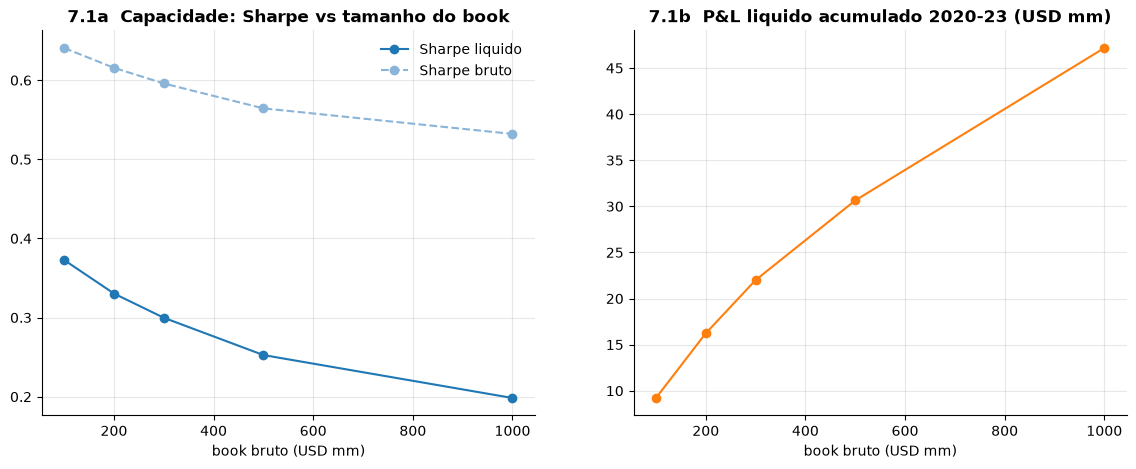

,sharpe_bruto,sharpe_liquido,ret_liquido_pct_aa,pnl_liquido_usd_mm,custos_bps_ano,turnover_x_ano
book_usd_mm,,,,,,
100.0,0.641,0.373,2.308,9.212,165.345,19.893
200.0,0.616,0.330,2.033,16.230,174.985,18.551
300.0,0.596,0.300,1.837,22.000,180.891,17.688
500.0,0.564,0.253,1.535,30.639,188.896,16.585
1000.0,0.532,0.198,1.182,47.173,198.271,15.059


In [12]:
# ---- Curva de capacidade: Sharpe liquido e P&L por tamanho de book ----
# Cada linha veio de um backtest COMPLETO (dev+val) naquele tamanho.
curva_capacidade = pd.read_parquet(raiz_projeto / "reports" / "capacity_analysis.parquet")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
curva_capacidade["sharpe_liquido"].plot(ax=eixos[0], marker="o",
                                        color=PALETTE["strategy"], label="Sharpe liquido")
curva_capacidade["sharpe_bruto"].plot(ax=eixos[0], marker="o", ls="--",
                                      color=PALETTE["gross"], label="Sharpe bruto")
eixos[0].set_title("7.1a  Capacidade: Sharpe vs tamanho do book")
eixos[0].set_xlabel("book bruto (USD mm)"); eixos[0].legend()
curva_capacidade["pnl_liquido_usd_mm"].plot(ax=eixos[1], marker="o", color=PALETTE["cost"])
eixos[1].set_title("7.1b  P&L liquido acumulado 2020-23 (USD mm)")
eixos[1].set_xlabel("book bruto (USD mm)")
plt.show()

curva_capacidade.round(3)

### 7.2 Regime de volatilidade — quando a estratégia ganha (e quando não há o que ganhar)

2023 foi negativo. **Decaimento do alfa ou dependência de regime?** Para separar as
hipóteses, o desempenho E a qualidade pura do sinal (IC) foram medidos por **tercil da
volatilidade realizada 21d do SPY**, defasada em 1 dia
(`scripts/12_regime_analysis.py`).

O teste decisivo é o **IC por regime**: se em vol baixa o IC for ~zero, não é que a
estratégia "perde" em mercado calmo — é que **o fenômeno não existe** ali. Isso é
exatamente o que a tese de **provisão de liquidez** prevê: sem estresse, não há
vendedores apressados, não há sobre-reação, não há reversão a capturar.

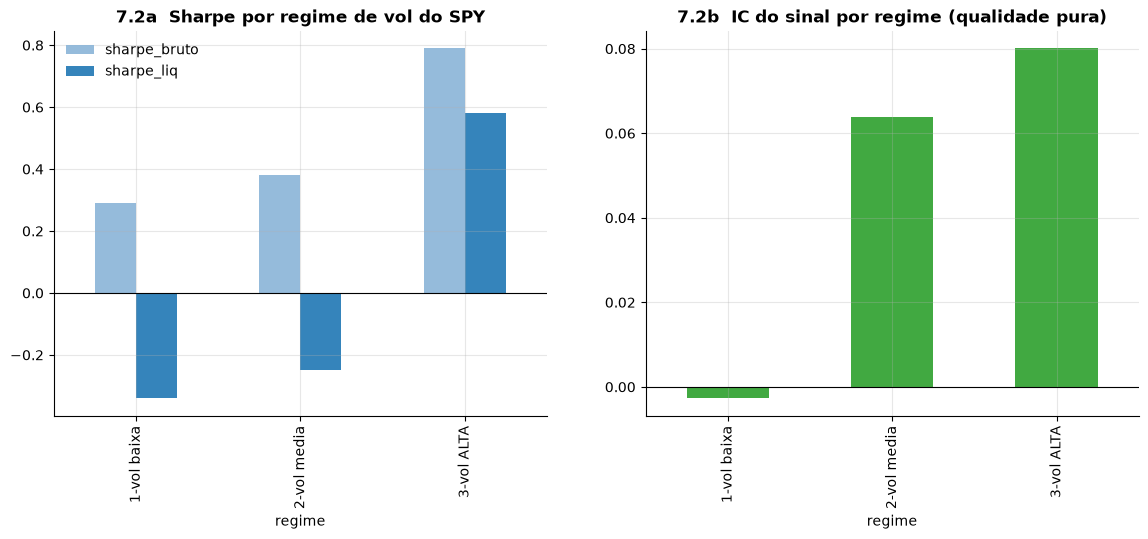

Desempenho por regime:
             n_dias vol_spy_media  ret_bruto_aa  sharpe_bruto  ret_liq_aa  sharpe_liq
regime                                                                               
1-vol baixa     336           10%          0.86          0.29       -1.02       -0.34
2-vol media     335           16%          1.25          0.38       -0.81       -0.25
3-vol ALTA      335           30%          7.39          0.79        5.39        0.58

IC por regime:
             ic_medio  t_stat  n_datas
regime                                
1-vol baixa   -0.0027 -0.1883       65
2-vol media    0.0639  3.3881       65
3-vol ALTA     0.0801  4.1217       67

Contexto anual: 2020 vol 26% | 2021 vol 12% | 2022 vol 24% | 2023 vol 13%
=> 2023 (vol baixa) nao foi decaimento: foi REGIME. Em vol baixa o IC e ~0 --
   o fenomeno que exploramos (sobre-reacao a fluxo) simplesmente nao ocorre.


In [13]:
# ---- Desempenho e IC por regime de volatilidade (tabelas do script 12) ----
desempenho_por_regime = pd.read_parquet(raiz_projeto / "reports" / "regime_pnl.parquet")
ic_por_regime = pd.read_parquet(raiz_projeto / "reports" / "regime_ic.parquet")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
desempenho_por_regime[["sharpe_bruto", "sharpe_liq"]].plot(
    kind="bar", ax=eixos[0], color=[PALETTE["gross"], PALETTE["strategy"]], alpha=0.9)
eixos[0].axhline(0, color="k", lw=0.8)
eixos[0].set_title("7.2a  Sharpe por regime de vol do SPY")
ic_por_regime["ic_medio"].plot(kind="bar", ax=eixos[1], color=PALETTE["iwm"], alpha=0.9)
eixos[1].axhline(0, color="k", lw=0.8)
eixos[1].set_title("7.2b  IC do sinal por regime (qualidade pura)")
plt.show()

print("Desempenho por regime:"); print(desempenho_por_regime.to_string())
print(); print("IC por regime:"); print(ic_por_regime.to_string())
print()
print("Contexto anual: 2020 vol 26% | 2021 vol 12% | 2022 vol 24% | 2023 vol 13%")
print("=> 2023 (vol baixa) nao foi decaimento: foi REGIME. Em vol baixa o IC e ~0 --")
print("   o fenomeno que exploramos (sobre-reacao a fluxo) simplesmente nao ocorre.")

## 8. Estado, próximos passos e glossário

### 8.1 O que já está validado

1. **Pipeline**: recuperou alfa plantado em painel sintético (gabarito), P&L verificado
   contra a biblioteca `bt` (corr 0,996), 14 testes automáticos (anti-lookahead de 9
   sinais, neutralidade + setor, custos convexos);
2. **Dados**: S&P 500 as-of com viés de seleção resolvido e viés de dados quantificado
   (92% membros; removidos 46% vs 99% sobreviventes);
3. **Sinal**: `resid_ou` escolhido por evidência (11 candidatos testados no total;
   blend descartado duas vezes por não agregar);
4. **Backtest oficial dev+val** rodado com mandato completo (seção 7).

### 8.2 Próximos passos

1. **Análise crítica** dos resultados (custos, capacidade, crises 2020/2022);
2. **Ida única ao holdout** (2024+) — o número final da estratégia;
3. **Relatório de 5 páginas + robô** (prazos: pré-relatório 31/07, final 17/08).

### 8.3 Glossário

| Termo | Significado |
|---|---|
| **Alfa** | retorno que vem de *prever*, não de carregar risco de mercado |
| **Fator / beta** | movimento coletivo (mercado, valor, momentum...) / sensibilidade a ele |
| **Resíduo (idiossincrático)** | o pedaço do retorno que os fatores não explicam |
| **Composição as-of** | o índice como era em cada data (mata o viés de sobrevivência) |
| **Reversão à média** | tendência de valores esticados voltarem ao nível normal |
| **Retorno idiossincrático acumulado** | soma dos resíduos numa janela; o quanto a ação andou "por conta própria" |
| **Métrica × sinal** | métrica = número por ação (contra si mesma); sinal = métrica padronizada entre as ações |
| **z-score temporal** | medida padronizada de uma ação contra o próprio histórico |
| **z-score cross-sectional** | padronização entre ações no mesmo dia (média 0, dp 1) |
| **IC** | correlação sinal → retorno futuro; 0,03–0,05 já é bom |
| **Dev / validação / holdout** | janelas separadas p/ evitar overfitting; holdout = uma ida |
| **Dollar-neutral / fator-neutro** | $long=$short / exposição ~0 a cada fator |
| **ADV / turnover / gross / net** | volume médio diário / giro / soma \|posições\| / líquido |
| **Almgren-Chriss** | modelo de custo: spread + impacto temporário (√) + permanente |